# Control Landscape Degeneracy With Parcellation Scale

This notebook collects the results for the landscape-degeneracy section. It is meant to make it easy to:

- inspect how control-energy landscapes change across scales and driver-set sizes,
- quantify sampling coverage relative to the full combinatorial space,
- compare summaries on both absolute `k` and normalized `k/N` axes,
- test whether the same qualitative pattern persists under a fraction-matched (`~5%`) robustness analysis,
- generate the main figures for the section.

The primary saved outputs cover `k in {1, 2, 3, 5}`. In addition, this notebook now includes a dedicated full-cohort robustness rerun at approximately `5%` of nodes per scale, allowing a direct check of whether increasing degeneracy with parcellation scale persists when driver-set size is matched as a fraction of network size.


In [12]:
from pathlib import Path
import os
import sys
from math import comb

os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

REPO_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RESULTS_DIR = REPO_ROOT / 'results'
FIGURES_DIR = REPO_ROOT / 'figures' / 'section_landscape_degeneracy'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(context='talk', style='whitegrid')

In [13]:
landscape = pd.read_csv(RESULTS_DIR / 'primary' / 'landscape_summary.csv')
scale_metadata = pd.read_csv(RESULTS_DIR / 'metadata' / 'scale_metadata.csv')
landscape = landscape.merge(scale_metadata[['scale', 'n_regions']], on='scale', how='left')
landscape['k_fraction'] = landscape['k'] / landscape['n_regions']
landscape['k_percent'] = 100.0 * landscape['k_fraction']
landscape.head()

,subject_id,scale,k,n_candidate_sets,enumerated_exactly,variance_log10_energy,best_energy,q05_log10_energy,q25_log10_energy,q50_log10_energy,q75_log10_energy,q95_log10_energy,near_optimal_fraction_01pct,near_optimal_fraction_05pct,near_optimal_fraction_10pct,n_regions,k_fraction,k_percent
0,sub-000,68,1,68,True,0.000019,6.300959e+06,6.799707,6.800816,6.803208,6.806241,6.811726,0.558824,1.00000,1.0000,68,0.014706,1.470588
1,sub-000,68,2,2278,True,0.000022,5.941449e+06,6.775301,6.777652,6.780126,6.783646,6.790108,0.302019,0.99122,1.0000,68,0.029412,2.941176
2,sub-000,68,3,5000,False,0.000027,5.606310e+06,6.751917,6.754798,6.757536,6.761719,6.768548,0.103200,0.96280,1.0000,68,0.044118,4.411765
3,sub-000,68,5,5000,False,0.000040,5.012972e+06,6.704968,6.708779,6.712799,6.717457,6.724906,0.034000,0.88200,0.9996,68,0.073529,7.352941
4,sub-001,68,1,68,True,0.000012,6.354095e+06,6.803258,6.804886,6.806757,6.808801,6.814462,0.544118,1.00000,1.0000,68,0.014706,1.470588


## Sampling coverage

In [14]:
coverage = (
    landscape[['scale', 'k', 'n_regions', 'n_candidate_sets', 'enumerated_exactly']]
    .drop_duplicates()
    .sort_values(['scale', 'k'])
    .reset_index(drop=True)
)
coverage['n_total_combinations'] = coverage.apply(lambda row: comb(int(row['n_regions']), int(row['k'])), axis=1)
coverage['sample_fraction'] = coverage['n_candidate_sets'] / coverage['n_total_combinations']
coverage['sample_percent'] = 100.0 * coverage['sample_fraction']
coverage['k_percent'] = 100.0 * coverage['k'] / coverage['n_regions']
coverage

,scale,k,n_regions,n_candidate_sets,enumerated_exactly,n_total_combinations,sample_fraction,sample_percent,k_percent
0,68,1,68,68,True,68,1.000000,100.000000,1.470588
1,68,2,68,2278,True,2278,1.000000,100.000000,2.941176
2,68,3,68,5000,False,50116,0.099769,9.976854,4.411765
3,68,5,68,5000,False,10424128,0.000480,0.047966,7.352941
4,114,1,114,114,True,114,1.000000,100.000000,0.877193
5,114,2,114,5000,False,6441,0.776277,77.627698,1.754386
6,114,3,114,5000,False,240464,0.020793,2.079313,2.631579
7,114,5,114,5000,False,146803272,0.000034,0.003406,4.385965
8,219,1,219,219,True,219,1.000000,100.000000,0.456621
9,219,2,219,5000,False,23871,0.209459,20.945918,0.913242


In [15]:
coverage_display = coverage.copy()
coverage_display['k_percent'] = coverage_display['k_percent'].map(lambda x: f'{x:.2f}%')
coverage_display['sample_fraction'] = coverage_display['sample_fraction'].map(lambda x: f'{x:.6g}')
coverage_display['sample_percent'] = coverage_display['sample_percent'].map(lambda x: f'{x:.4f}%')
coverage_display[['scale', 'k', 'k_percent', 'n_candidate_sets', 'n_total_combinations', 'sample_fraction', 'sample_percent', 'enumerated_exactly']]

,scale,k,k_percent,n_candidate_sets,n_total_combinations,sample_fraction,sample_percent,enumerated_exactly
0,68,1,1.47%,68,68,1,100.0000%,True
1,68,2,2.94%,2278,2278,1,100.0000%,True
2,68,3,4.41%,5000,50116,0.0997685,9.9769%,False
3,68,5,7.35%,5000,10424128,0.000479656,0.0480%,False
4,114,1,0.88%,114,114,1,100.0000%,True
5,114,2,1.75%,5000,6441,0.776277,77.6277%,False
6,114,3,2.63%,5000,240464,0.0207931,2.0793%,False
7,114,5,4.39%,5000,146803272,3.40592e-05,0.0034%,False
8,219,1,0.46%,219,219,1,100.0000%,True
9,219,2,0.91%,5000,23871,0.209459,20.9459%,False


## Subject-averaged landscape summaries

In [16]:
summary = (
    landscape.groupby(['scale', 'k', 'n_regions', 'k_fraction', 'k_percent'], as_index=False)
    .agg(
        n_subjects=('subject_id', 'nunique'),
        mean_variance_log10_energy=('variance_log10_energy', 'mean'),
        sem_variance_log10_energy=('variance_log10_energy', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_near_optimal_05=('near_optimal_fraction_05pct', 'mean'),
        sem_near_optimal_05=('near_optimal_fraction_05pct', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_q50_log10_energy=('q50_log10_energy', 'mean'),
        mean_q05_log10_energy=('q05_log10_energy', 'mean'),
        mean_q95_log10_energy=('q95_log10_energy', 'mean'),
    )
)
summary

,scale,k,n_regions,k_fraction,k_percent,n_subjects,mean_variance_log10_energy,sem_variance_log10_energy,mean_near_optimal_05,sem_near_optimal_05,mean_q50_log10_energy,mean_q05_log10_energy,mean_q95_log10_energy
0,68,1,68,0.014706,1.470588,70,0.000018,6.183098e-07,0.996429,0.001012,6.807056,6.802203,6.815563
1,68,2,68,0.029412,2.941176,70,0.000020,6.569304e-07,0.983225,0.002215,6.786267,6.780707,6.795116
2,68,3,68,0.044118,4.411765,70,0.000025,6.670319e-07,0.962149,0.003778,6.765939,6.759540,6.775611
3,68,5,68,0.073529,7.352941,70,0.000035,7.695409e-07,0.870094,0.006506,6.725009,6.717133,6.736284
4,114,1,114,0.008772,0.877193,70,0.000007,1.880907e-07,1.000000,0.000000,7.042578,7.039243,7.047182
5,114,2,114,0.017544,1.754386,70,0.000007,2.150238e-07,0.999986,0.000010,7.030412,7.026879,7.035551
6,114,3,114,0.026316,2.631579,70,0.000008,2.205814e-07,0.999934,0.000023,7.018703,7.014786,7.024047
7,114,5,114,0.043860,4.385965,70,0.000011,2.429617e-07,0.999129,0.000199,6.995448,6.990836,7.001547
8,219,1,219,0.004566,0.456621,70,0.000002,5.231895e-08,1.000000,0.000000,7.333742,7.331047,7.335863
9,219,2,219,0.009132,0.913242,70,0.000003,7.051761e-08,1.000000,0.000000,7.327118,7.324718,7.330292


## Figure: landscape summary on the native k axis

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_landscape_degeneracy/landscape_summary_native_k.svg')

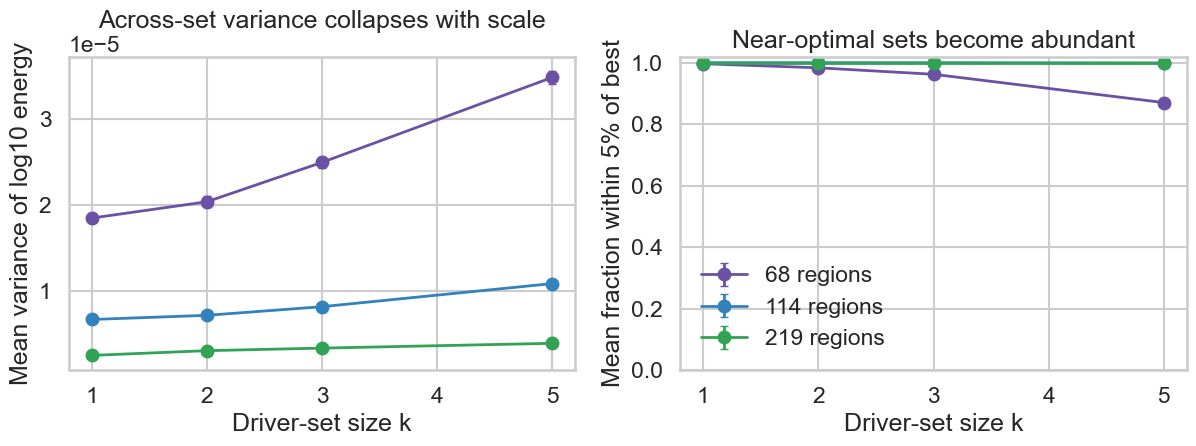

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
palette = {68: '#6a51a3', 114: '#3182bd', 219: '#31a354'}

for scale in sorted(summary['scale'].unique()):
    subset = summary[summary['scale'] == scale].sort_values('k')
    axes[0].errorbar(
        subset['k'],
        subset['mean_variance_log10_energy'],
        yerr=subset['sem_variance_log10_energy'],
        marker='o',
        linewidth=2,
        capsize=3,
        color=palette[scale],
        label=f'{scale} regions',
    )
    axes[1].errorbar(
        subset['k'],
        subset['mean_near_optimal_05'],
        yerr=subset['sem_near_optimal_05'],
        marker='o',
        linewidth=2,
        capsize=3,
        color=palette[scale],
        label=f'{scale} regions',
    )

axes[0].set_xlabel('Driver-set size k')
axes[0].set_ylabel('Mean variance of log10 energy')
axes[0].set_title('Across-set variance collapses with scale')
axes[1].set_xlabel('Driver-set size k')
axes[1].set_ylabel('Mean fraction within 5% of best')
axes[1].set_title('Near-optimal sets become abundant')
axes[1].set_ylim(0.0, 1.02)
axes[1].legend(frameon=False, title='')
fig.tight_layout()
out = FIGURES_DIR / 'landscape_summary_native_k.svg'
fig.savefig(out, bbox_inches='tight')
out

## Figure: landscape summary on the normalized k/N axis

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_landscape_degeneracy/landscape_summary_normalized_k_fraction.svg')

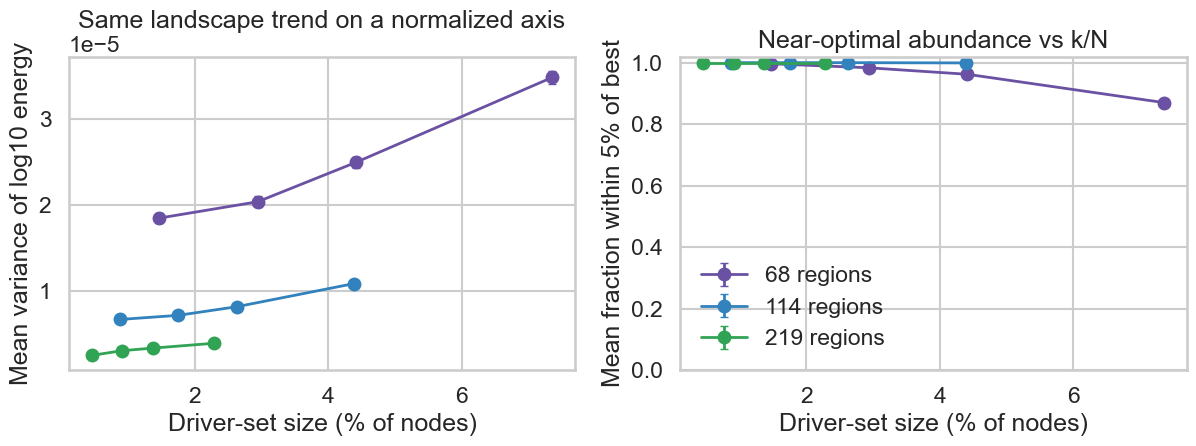

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
palette = {68: '#6a51a3', 114: '#3182bd', 219: '#31a354'}

for scale in sorted(summary['scale'].unique()):
    subset = summary[summary['scale'] == scale].sort_values('k_fraction')
    axes[0].errorbar(
        subset['k_percent'],
        subset['mean_variance_log10_energy'],
        yerr=subset['sem_variance_log10_energy'],
        marker='o',
        linewidth=2,
        capsize=3,
        color=palette[scale],
        label=f'{scale} regions',
    )
    axes[1].errorbar(
        subset['k_percent'],
        subset['mean_near_optimal_05'],
        yerr=subset['sem_near_optimal_05'],
        marker='o',
        linewidth=2,
        capsize=3,
        color=palette[scale],
        label=f'{scale} regions',
    )

axes[0].set_xlabel('Driver-set size (% of nodes)')
axes[0].set_ylabel('Mean variance of log10 energy')
axes[0].set_title('Same landscape trend on a normalized axis')
axes[1].set_xlabel('Driver-set size (% of nodes)')
axes[1].set_ylabel('Mean fraction within 5% of best')
axes[1].set_title('Near-optimal abundance vs k/N')
axes[1].set_ylim(0.0, 1.02)
axes[1].legend(frameon=False, title='')
fig.tight_layout()
out = FIGURES_DIR / 'landscape_summary_normalized_k_fraction.svg'
fig.savefig(out, bbox_inches='tight')
out

## Fraction-matched 5% robustness check

In [19]:
landscape_5pct = pd.read_csv(REPO_ROOT / 'results_fraction_5pct' / 'robustness' / 'sensitivity_summary.csv')
# landscape summaries are duplicated across the two methods; keep one copy per subject/scale/k
landscape_5pct = landscape_5pct[landscape_5pct['method'] == 'degree_strength'].copy()
landscape_5pct = landscape_5pct.merge(scale_metadata[['scale', 'n_regions']], on='scale', how='left')
landscape_5pct['k_fraction'] = landscape_5pct['k'] / landscape_5pct['n_regions']
landscape_5pct['k_percent'] = 100.0 * landscape_5pct['k_fraction']

summary_5pct = (
    landscape_5pct.groupby(['scale', 'k', 'n_regions', 'k_fraction', 'k_percent'], as_index=False)
    .agg(
        n_subjects=('subject_id', 'nunique'),
        mean_variance_log10_energy=('variance_log10_energy', 'mean'),
        sem_variance_log10_energy=('variance_log10_energy', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_near_optimal_05=('near_optimal_fraction_05pct', 'mean'),
        sem_near_optimal_05=('near_optimal_fraction_05pct', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
)
summary_5pct

,scale,k,n_regions,k_fraction,k_percent,n_subjects,mean_variance_log10_energy,sem_variance_log10_energy,mean_near_optimal_05,sem_near_optimal_05
0,68,3,68,0.044118,4.411765,70,0.000025,6.900202e-07,0.961654,0.003710
1,114,6,114,0.052632,5.263158,70,0.000012,2.577452e-07,0.997423,0.000540
2,219,11,219,0.050228,5.022831,70,0.000006,9.259995e-08,0.999997,0.000003


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_landscape_degeneracy/landscape_fraction_matched_5pct.svg')

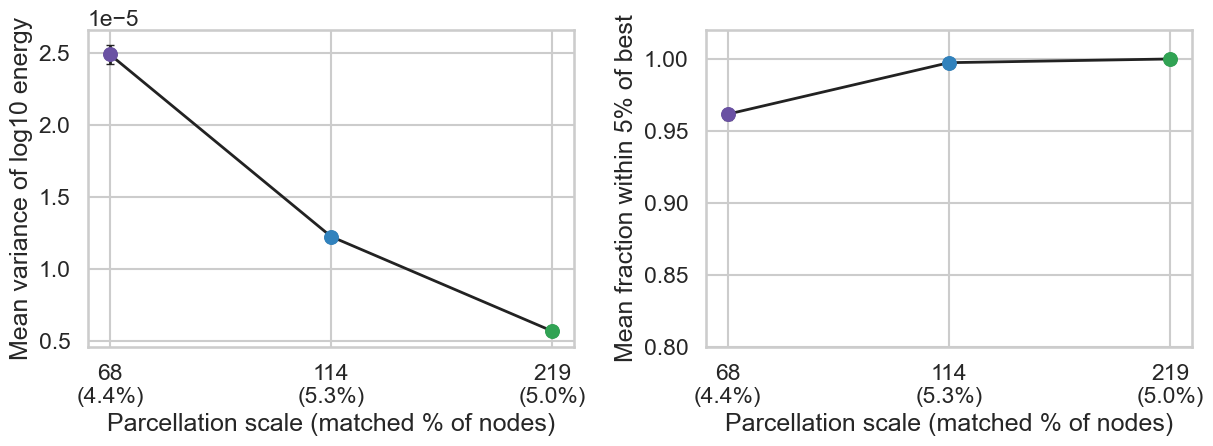

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
palette = {68: '#6a51a3', 114: '#3182bd', 219: '#31a354'}
subset = summary_5pct.sort_values('scale').copy()
subset['scale_label'] = subset.apply(lambda row: f"{int(row['scale'])}\n({row['k_percent']:.1f}%)", axis=1)
x = np.arange(len(subset))

axes[0].errorbar(
    x,
    subset['mean_variance_log10_energy'],
    yerr=subset['sem_variance_log10_energy'],
    marker='o',
    linewidth=2,
    capsize=3,
    color='#222222',
)
for xi, row in zip(x, subset.itertuples(index=False)):
    axes[0].scatter(xi, row.mean_variance_log10_energy, s=85, color=palette[row.scale], zorder=3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(subset['scale_label'])
axes[0].set_xlabel('Parcellation scale (matched % of nodes)')
axes[0].set_ylabel('Mean variance of log10 energy')
# axes[0].set_title('Fraction-matched (~5%) variance still drops with scale')

axes[1].errorbar(
    x,
    subset['mean_near_optimal_05'],
    yerr=subset['sem_near_optimal_05'],
    marker='o',
    linewidth=2,
    capsize=3,
    color='#222222',
)
for xi, row in zip(x, subset.itertuples(index=False)):
    axes[1].scatter(xi, row.mean_near_optimal_05, s=85, color=palette[row.scale], zorder=3)
axes[1].set_xticks(x)
axes[1].set_xticklabels(subset['scale_label'])
axes[1].set_xlabel('Parcellation scale (matched % of nodes)')
axes[1].set_ylabel('Mean fraction within 5% of best')
axes[1].set_ylim(0.8, 1.02)
# axes[1].set_title('Near-optimal abundance still rises at ~5% support')
fig.tight_layout()
out = FIGURES_DIR / 'landscape_fraction_matched_5pct.svg'
fig.savefig(out, bbox_inches='tight')
out


## Figure: heatmaps of the landscape summaries

/var/folders/fg/dc68zxv12sz5v55n18sqsvmw0000gn/T/ipykernel_61236/1774762251.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.85e-05
(1.5%)' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  ann_var.loc[k_value, scale_value] = f"{variance_mat.loc[k_value, scale_value]:.2e}\n({ann_var.loc[k_value, scale_value]:.1f}%)"
/var/folders/fg/dc68zxv12sz5v55n18sqsvmw0000gn/T/ipykernel_61236/1774762251.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '6.66e-06
(0.9%)' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  ann_var.loc[k_value, scale_value] = f"{variance_mat.loc[k_value, scale_value]:.2e}\n({ann_var.loc[k_value, scale_value]:.1f}%)"
/var/folders/fg/dc68zxv12sz5v55n18sqsvmw0000gn/T/ipykernel_61236/1774762251.py:6: FutureWarning: Setting a

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_landscape_degeneracy/landscape_heatmaps.svg')

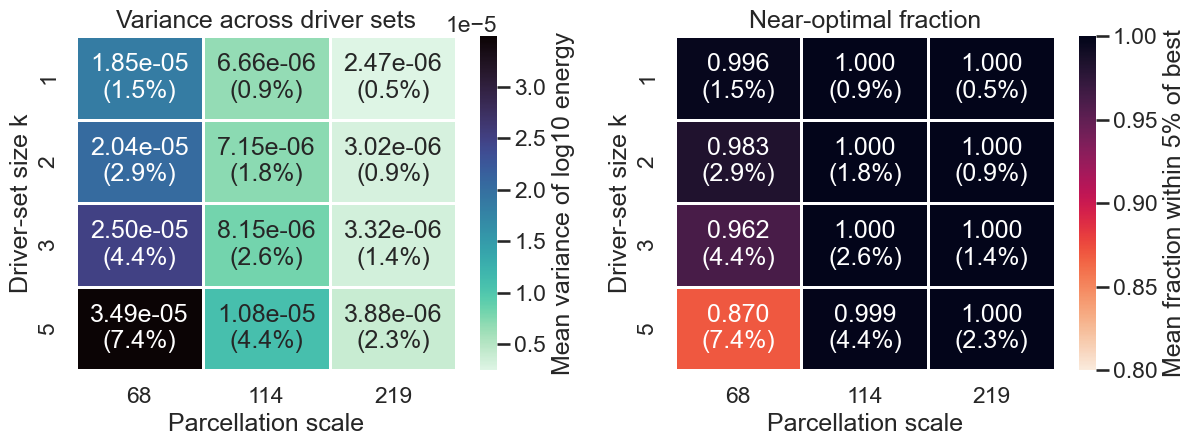

In [26]:
variance_mat = summary.pivot(index='k', columns='scale', values='mean_variance_log10_energy').sort_index()
nearopt_mat = summary.pivot(index='k', columns='scale', values='mean_near_optimal_05').sort_index()
ann_var = summary.pivot(index='k', columns='scale', values='k_percent').sort_index().copy()
for k_value in ann_var.index:
    for scale_value in ann_var.columns:
        ann_var.loc[k_value, scale_value] = f"{variance_mat.loc[k_value, scale_value]:.2e}\n({ann_var.loc[k_value, scale_value]:.1f}%)"
ann_opt = summary.pivot(index='k', columns='scale', values='k_percent').sort_index().copy()
for k_value in ann_opt.index:
    for scale_value in ann_opt.columns:
        ann_opt.loc[k_value, scale_value] = f"{nearopt_mat.loc[k_value, scale_value]:.3f}\n({ann_opt.loc[k_value, scale_value]:.1f}%)"

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
sns.heatmap(variance_mat, annot=ann_var, fmt='', cmap='mako_r', linewidths=0.8, linecolor='white', cbar_kws={'label': 'Mean variance of log10 energy'}, ax=axes[0])
axes[0].set_title('Variance across driver sets')
axes[0].set_xlabel('Parcellation scale')
axes[0].set_ylabel('Driver-set size k')
sns.heatmap(nearopt_mat, annot=ann_opt, fmt='', cmap='rocket_r', vmin=0.8, vmax=1.0, linewidths=0.8, linecolor='white', cbar_kws={'label': 'Mean fraction within 5% of best'}, ax=axes[1])
axes[1].set_title('Near-optimal fraction')
axes[1].set_xlabel('Parcellation scale')
axes[1].set_ylabel('Driver-set size k')
fig.tight_layout()
out = FIGURES_DIR / 'landscape_heatmaps.svg'
fig.savefig(out, bbox_inches='tight')
out

## Figure: coverage of sampled versus full combinatorial space

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_landscape_degeneracy/landscape_sampling_coverage.svg')

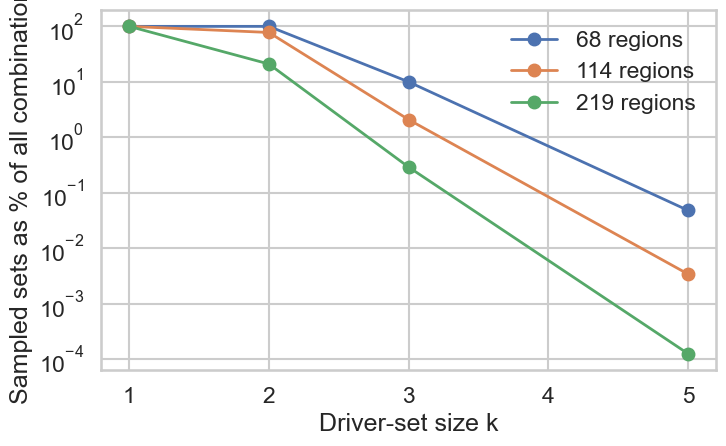

In [24]:
fig, ax = plt.subplots(figsize=(7.6, 4.8))
for scale, subset in coverage.groupby('scale'):
    subset = subset.sort_values('k')
    ax.plot(subset['k'], subset['sample_percent'], marker='o', linewidth=2, label=f'{scale} regions')
ax.set_yscale('log')
ax.set_xlabel('Driver-set size k')
ax.set_ylabel('Sampled sets as % of all combinations')
# ax.set_title('Sampling coverage drops sharply as k and scale increase')
ax.legend(frameon=False, title='')
fig.tight_layout()
out = FIGURES_DIR / 'landscape_sampling_coverage.svg'
fig.savefig(out, bbox_inches='tight')
out

## Notes for interpretation

In [23]:
for _, row in summary.sort_values(['scale', 'k']).iterrows():
    print(
        f"Scale {int(row['scale'])}, k={int(row['k'])} ({row['k_percent']:.2f}%): "
        f"variance = {row['mean_variance_log10_energy']:.2e}, "
        f"near-optimal fraction = {row['mean_near_optimal_05']:.3f}"
    )

Scale 68, k=1 (1.47%): variance = 1.85e-05, near-optimal fraction = 0.996
Scale 68, k=2 (2.94%): variance = 2.04e-05, near-optimal fraction = 0.983
Scale 68, k=3 (4.41%): variance = 2.50e-05, near-optimal fraction = 0.962
Scale 68, k=5 (7.35%): variance = 3.49e-05, near-optimal fraction = 0.870
Scale 114, k=1 (0.88%): variance = 6.66e-06, near-optimal fraction = 1.000
Scale 114, k=2 (1.75%): variance = 7.15e-06, near-optimal fraction = 1.000
Scale 114, k=3 (2.63%): variance = 8.15e-06, near-optimal fraction = 1.000
Scale 114, k=5 (4.39%): variance = 1.08e-05, near-optimal fraction = 0.999
Scale 219, k=1 (0.46%): variance = 2.47e-06, near-optimal fraction = 1.000
Scale 219, k=2 (0.91%): variance = 3.02e-06, near-optimal fraction = 1.000
Scale 219, k=3 (1.37%): variance = 3.32e-06, near-optimal fraction = 1.000
Scale 219, k=5 (2.28%): variance = 3.88e-06, near-optimal fraction = 1.000
